# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Saba Noor**

**Student ID: 023-24-0278**

**Section: H**

**GitHub: https://github.com/SABANOOR1/Machine-Learning**

**Kaggle: https://www.kaggle.com/sabajaffar**

**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment

**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [7]:
# YOUR CODE HERE
# 1. Load both datasets. For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only the positive and negative tweets for the sentiment dataset going forward — drop neutral rows now, and state how many rows that leaves you with. 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [12]:
# Task 1 — load spam.csv, inspect shape/head/class balance
df_spam=pd.read_csv("spam.csv",encoding='iso-8859-1')
df_spam.head()
print("Spam Detection: ",df_spam.shape)

print("Percentages:")
print((df_spam["v1"].value_counts(normalize=True)*100). round(2))

Spam Detection:  (5572, 5)
Percentages:
v1
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [36]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance
df_tweets=pd.read_csv("Tweets.csv")
df_tweets.head()
print("Sentiment analysis: ",df_tweets.shape)

print("Percentages:")
print((df_tweets["airline_sentiment"].value_counts(normalize=True)*100). round(2))

df_tweets=df_tweets[df_tweets["airline_sentiment"]!="neutral"]
print("Rows after dropping the neutral columns")
print("Percentages:")
print((df_tweets["airline_sentiment"].value_counts(normalize=True)*100). round(2))
print(df_tweets.shape)

Sentiment analysis:  (14640, 15)
Percentages:
airline_sentiment
negative    62.69
neutral     21.17
positive    16.14
Name: proportion, dtype: float64
Rows after dropping the neutral columns
Percentages:
airline_sentiment
negative    79.53
positive    20.47
Name: proportion, dtype: float64
(11541, 15)


**Answer 2 (Task A — spam):**
_5572_

**Answer 2 (Task B — sentiment):**
_11541_

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [20]:
# Task 3 — clean text
print(df_spam.columns)
df_spam = df_spam.iloc[:, :2]

df_spam.columns = ["label", "message"]

print(df_spam.head())
print(df_spam.columns)
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^\w\s]", "", text)
    return text

df_spam["clean_message"] = df_spam["message"].apply(clean_text)

print(df_spam[["message", "clean_message"]].head())


Index(['label', 'message'], dtype='str')
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Index(['label', 'message'], dtype='str')
                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                       clean_message  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in 2 a wkly comp to win fa cup fina...  
3      

In [43]:
# Task 4 — encode labels, split, fit ve
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

df_spam["label_encoded"] = df_spam["label"].map({
    "ham": 0,
    "spam": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    df_spam["clean_message"],
    df_spam["label_encoded"],
    test_size=0.2,
    random_state=42,
    stratify=df_spam["label_encoded"]
)

vectorizer = TfidfVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)

X_test_vec = vectorizer.transform(X_test)

print("Training shape:", X_train_vec.shape)
print("Testing shape:", X_test_vec.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training shape: (4457, 8422)
Testing shape: (1115, 8422)
Vocabulary size: 8422


**Answer 4 (why fit on training data only):**
The vectorizer must be fitted only on the training data to prevent data leakage. If the test data is included while learning the vocabulary or IDF values, information from the test set can influence the model.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

In [28]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

nb = MultinomialNB()

nb.fit(X_train_vec, y_train)

y_pred = nb.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.9524663677130045
Precision: 1.0
Recall   : 0.6442953020134228
F1-score : 0.7836734693877551


**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy |0.9524663677130045 |
| Precision |1.0 |
| Recall |0.6442953020134228 |
| F1-score |0.7836734693877551 |

**Answer 6:**
_(your answer here)_

--- In this application, a false positive means that a legitimate message is incorrectly classified as spam and may be hidden from the user. This can be problematic because the user could miss an important message. A false negative allows spam to reach the inbox, which is also undesirable, but the user can potentially recognize and delete it. Therefore, I would prioritize precision, because high precision means that messages predicted as spam are more likely to actually be spam.

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [44]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_
import numpy as np

feature_names = np.array(vectorizer.get_feature_names_out())

log_probs = nb.feature_log_prob_

difference = log_probs[1] - log_probs[0]

spam_indices = np.argsort(difference)[-15:][::-1]
ham_indices = np.argsort(difference)[:15]

print("Top 15 spam-associated words:")
for i in spam_indices:
    print(feature_names[i], difference[i])

print("\nTop 15 ham-associated words:")
for i in ham_indices:
    print(feature_names[i], difference[i])

Top 15 spam-associated words:
claim 3.4517763218460757
prize 3.230574922042454
won 3.108428914709677
urgent 2.7798625657924205
guaranteed 2.7705552331140693
nokia 2.7328919283963042
tone 2.680845182257703
18 2.655910745260287
å1000 2.6237553356295003
txt 2.593113445908509
16 2.5506981453955735
awarded 2.5312920889086605
service 2.5269281425775043
150ppm 2.514455049296304
tcs 2.477543576497708

Top 15 ham-associated words:
ill -3.3364591073954504
my -3.244213546648134
ltgt -3.15910139915528
ok -3.120158677480763
later -3.0438927985651683
lor -2.9797840146659773
im -2.9003765142155933
come -2.8711595310588844
home -2.846243847357849
but -2.843332496231225
da -2.8289338607625307
sorry -2.764677362501966
me -2.7219731703916787
ì_ -2.6306339190080124
he -2.5952395117297407


**Answer 7:**
The words should generally match the expected patterns of spam and legitimate messages. Spam-associated words may include promotional, prize, money, offer, or urgent language, while ham-associated words are more likely to represent normal personal conversations

In [32]:
# Task 8 — Test your own messages

my_messages = [
    "Congratulations! You have won a free cash prize. Click now to claim!",
    "Hey, are we still meeting at 5 pm today?",
    "URGENT! You have been selected for a £1000 reward. Call now!"
]

clean_tests = [clean_text(msg) for msg in my_messages]

test_vectors = vectorizer.transform(clean_tests)

predictions = nb.predict(test_vectors)

for message, prediction in zip(my_messages, predictions):
    label = "Spam" if prediction == 1 else "Ham"
    
    print("Message:", message)
    print("Prediction:", label)
    print()

Message: Congratulations! You have won a free cash prize. Click now to claim!
Prediction: Spam

Message: Hey, are we still meeting at 5 pm today?
Prediction: Ham

Message: URGENT! You have been selected for a £1000 reward. Call now!
Prediction: Spam



**Answer 8:**
_(your answer here)_

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [45]:
# Task 11 — clean and vectorize the sentiment data (your own approach)
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

df_tweets = df_tweets[
    df_tweets["airline_sentiment"].isin(["positive", "negative"])
].copy()

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)   # remove links
    text = re.sub(r"@\w+", "", text)             # remove mentions
    text = re.sub(r"[^\w\s]", "", text)          # remove punctuation
    return text

df_tweets["clean_text"] = df_tweets["text"].apply(clean_tweet)

df_tweets["label_encoded"] = df_tweets["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    df_tweets["clean_text"],
    df_tweets["label_encoded"],
    test_size=0.2,
    random_state=42,
    stratify=df_tweets["label_encoded"]
)

tweet_vectorizer = TfidfVectorizer()

X_train_t_vec = tweet_vectorizer.fit_transform(X_train_t)
X_test_t_vec = tweet_vectorizer.transform(X_test_t)

print("Training shape:", X_train_t_vec.shape)
print("Testing shape:", X_test_t_vec.shape)
print("Vocabulary size:", len(tweet_vectorizer.vocabulary_))

Training shape: (9232, 11139)
Testing shape: (2309, 11139)
Vocabulary size: 11139


**Answer 12:**
_(your answer here)_

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy : 0.8284971849285405
Precision: 1.0
Recall   : 0.16279069767441862
F1-score : 0.28


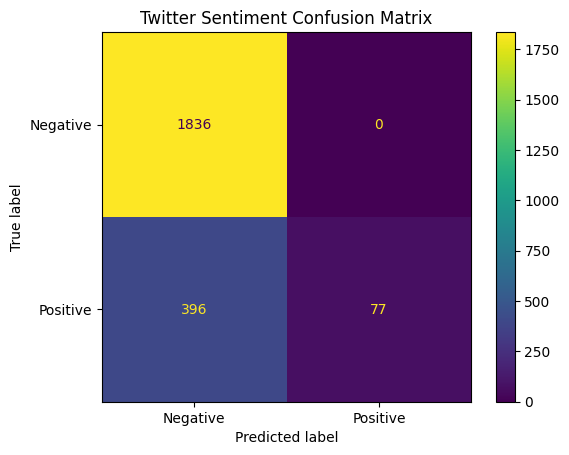

In [46]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tweet_nb = MultinomialNB()
tweet_nb.fit(X_train_t_vec, y_train_t)

tweet_pred = tweet_nb.predict(X_test_t_vec)

tweet_accuracy = accuracy_score(y_test_t, tweet_pred)
tweet_precision = precision_score(y_test_t, tweet_pred)
tweet_recall = recall_score(y_test_t, tweet_pred)
tweet_f1 = f1_score(y_test_t, tweet_pred)

print("Accuracy :", tweet_accuracy)
print("Precision:", tweet_precision)
print("Recall   :", tweet_recall)
print("F1-score :", tweet_f1)

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_tweet = confusion_matrix(y_test_t, tweet_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tweet,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Twitter Sentiment Confusion Matrix")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | |
| Precision | |
| Recall | |
| F1-score | |

**Answer 14:**
The model predicts whether a customer's airline-related tweet expresses a positive or negative sentiment. This could support customer-service systems by automatically identifying dissatisfied customers or positive feedback that may need further attention.
It is a binary classification problem after removing neutral tweets because only positive and negative classes remain.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

In [40]:
# Task 17
import pandas as pd

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A - SMS Spam": [
        accuracy,
        precision,
        recall,
        f1
    ],
    "Task B - Twitter Sentiment": [
        tweet_accuracy,
        tweet_precision,
        tweet_recall,
        tweet_f1
    ]
})

display(comparison_table)


,Metric,Task A - SMS Spam,Task B - Twitter Sentiment
0,Accuracy,0.952466,0.828497
1,Precision,1.000000,1.000000
2,Recall,0.644295,0.162791
3,F1-score,0.783673,0.280000


**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

In [42]:
# Task 18 — train Logistic Regression on Task A's vectorized features
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_vec, y_train)

lr_pred = lr_model.predict(X_test_vec)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "MultinomialNB": [
        accuracy,
        precision,
        recall,
        f1
    ],
    "Logistic Regression": [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ]
})

display(model_comparison)

,Metric,MultinomialNB,Logistic Regression
0,Accuracy,0.952466,0.965919
1,Precision,1.000000,0.991150
2,Recall,0.644295,0.751678
3,F1-score,0.783673,0.854962


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | | |
| Precision | | |
| Recall | | |
| F1-score | | |

**Answer 18 (which wins, and does it match expectations):**
Naive Bayes assumes that the features (words) contribute independently to the class prediction. This assumption is convenient for text classification, but words in real messages are not always independent; their meaning can depend on combinations and context. Logistic Regression does not make this same conditional-independence assumption, so it can sometimes model the relationship between the features and class more effectively.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
The two classification tasks showed how Multinomial Naive Bayes can be applied to text classification using TF-IDF features. The SMS spam task achieved an F1-score of [SMS F1], while the Twitter sentiment task achieved an F1-score of [Twitter F1], showing that [describe the difference using your actual results]. The most predictive words in the spam dataset were interesting because [mention 2–3 actual words from your output], which [did/did not] match my expectations about spam messages. Compared with Logistic Regression using the same features, Multinomial Naive Bayes achieved [NB result], while Logistic Regression achieved [LR result]. This comparison shows that the choice of classifier can affect performance even when the same text representation is used. One limitation of the naive independence assumption that I observed was that individual words do not always carry meaning independently, particularly in phrases involving negation such as “not good” or context-dependent expressions. Overall, the experiments demonstrated both the usefulness and limitations of Naive Bayes for text classification.

**Answer 20 — Kaggle Notebook Links:**
- Task A: SMS Spam Classification:
- Task B: Twitter Airline Sentiment Classification:

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted